# 00. Maestro de municipios — DIVIPOLA GEODANE
## Integración de fuentes de datos

Objetivo: construir un maestro territorial con una fila por DIVIPOLA, coordenadas geográficas y tipo de localización. Se conserva el universo territorial para poder evaluar cobertura antes de integrar IGAC.

Fuente principal: DIVIPOLA_Municipios GEODANE.xlsx, actualización indicada en el archivo: 30 de octubre de 2026.
No se excluyen grandes ciudades ni áreas no municipalizadas en esta etapa.

### 0. Importación de libreriras

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt

### 1. Estructura de carpetas

In [2]:
RAIZ = Path(r"C:\Users\ASUS ADMI\Downloads\11 Gerencia de Proyectos Analytics\Proyecto\proyecto_MIAD")
#RAIZ = Path.cwd().parent.parent - dejar

INTEGRACION = RAIZ / "Integracion"
ORIGINALES = INTEGRACION / "Datos_originales"
INTERMEDIOS = INTEGRACION / "Datos_intermedios"
PROCESADOS = INTEGRACION / "Datos_procesados"
RESULTADOS = INTEGRACION / "Resultados"
NOTEBOOKS = INTEGRACION / "Notebooks"

#Creación de carpetas
#for carpeta in [ORIGINALES, INTERMEDIOS, PROCESADOS, RESULTADOS, NOTEBOOKS]:
#    carpeta.mkdir(parents=True, exist_ok=True)

print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: C:\Users\ASUS ADMI\Downloads\11 Gerencia de Proyectos Analytics\Proyecto\proyecto_MIAD


### 2. Carga del catálogo GEODANE
La fila 11 de Excel contiene los encabezados. Los códigos y nombres repetidos corresponden a departamento y municipio respectivamente; se distinguen por su posición y espacios originales. Se retiran las notas y filas finales sin código territorial, sin alterar el archivo fuente.

In [3]:
# Leer archivo Excel
ARCHIVO = ORIGINALES / "DIVIPOLA_Municipios GEODANE.xlsx"

df = pd.read_excel(ARCHIVO,sheet_name="Municipios",header=10,dtype="string")
df.head()

,Código,Nombre,Código,Nombre,Municipio\nIsla\nÁrea no municipalizada,Longitud,Latitud,Nota
0,05,ANTIOQUIA,05001,MEDELLÍN,Municipio,-75.581775,6.246631,<NA>
1,05,ANTIOQUIA,05002,ABEJORRAL,Municipio,-75.428739,5.789315,<NA>
2,05,ANTIOQUIA,05004,ABRIAQUÍ,Municipio,-76.064304,6.632282,<NA>
3,05,ANTIOQUIA,05021,ALEJANDRÍA,Municipio,-75.141346,6.376061,<NA>
4,05,ANTIOQUIA,05030,AMAGÁ,Municipio,-75.702188,6.038708,<NA>


In [4]:
# Cambiar nombres de las columnas
df.columns = ["cod_depto","departamento","divipola","municipio","tipo_localizacion","longitud","latitud","nota"]

# Conservar únicamente los registros con código DIVIPOLA
df = df[df["divipola"].notna()].copy()

# Mostrar tabla
display(df.head(10))


,cod_depto,departamento,divipola,municipio,tipo_localizacion,longitud,latitud,nota
0,05,ANTIOQUIA,05001,MEDELLÍN,Municipio,-75.581775,6.246631,<NA>
1,05,ANTIOQUIA,05002,ABEJORRAL,Municipio,-75.428739,5.789315,<NA>
2,05,ANTIOQUIA,05004,ABRIAQUÍ,Municipio,-76.064304,6.632282,<NA>
3,05,ANTIOQUIA,05021,ALEJANDRÍA,Municipio,-75.141346,6.376061,<NA>
4,05,ANTIOQUIA,05030,AMAGÁ,Municipio,-75.702188,6.038708,<NA>
5,05,ANTIOQUIA,05031,AMALFI,Municipio,-75.077501,6.909655,<NA>
6,05,ANTIOQUIA,05034,ANDES,Municipio,-75.878828,5.657194,<NA>
7,05,ANTIOQUIA,05036,ANGELÓPOLIS,Municipio,-75.711389,6.109719,<NA>
8,05,ANTIOQUIA,05038,ANGOSTURA,Municipio,-75.335116,6.885175,<NA>
9,05,ANTIOQUIA,05040,ANORÍ,Municipio,-75.148355,7.074703,<NA>


### 3. Homologación de códigos, nombres y coordenadas
Se preservan los ceros iniciales.
Las coordenadas se convierten a valores numéricos en grados decimales; no se redondean ni se imputan valores. 
Se mantienen los nombres y las categorías del archivo oficial.

In [5]:
# Crear una copia del maestro sin la columna nota
maestro = df.drop(columns="nota").copy()

# Organizar códigos DIVIPOLA
maestro["cod_depto"] = maestro["cod_depto"].str.strip().str.zfill(2)
maestro["divipola"] = maestro["divipola"].str.strip().str.zfill(5)

# Crear código de municipio (últimos 3 dígitos)
maestro["cod_muni"] = maestro["divipola"].str[-3:]

# Limpiar nombres de departamentos y municipios
for columna in ["departamento", "municipio", "tipo_localizacion"]:
    maestro[columna] = maestro[columna].str.strip()

# Convertir coordenadas a números
maestro["longitud"] = pd.to_numeric(maestro["longitud"], errors="coerce")
maestro["latitud"] = pd.to_numeric(maestro["latitud"], errors="coerce")

# Mostrar tabla
display(maestro.head(10))


,cod_depto,departamento,divipola,municipio,tipo_localizacion,longitud,latitud,cod_muni
0,05,ANTIOQUIA,05001,MEDELLÍN,Municipio,-75.581775,6.246631,001
1,05,ANTIOQUIA,05002,ABEJORRAL,Municipio,-75.428739,5.789315,002
2,05,ANTIOQUIA,05004,ABRIAQUÍ,Municipio,-76.064304,6.632282,004
3,05,ANTIOQUIA,05021,ALEJANDRÍA,Municipio,-75.141346,6.376061,021
4,05,ANTIOQUIA,05030,AMAGÁ,Municipio,-75.702188,6.038708,030
5,05,ANTIOQUIA,05031,AMALFI,Municipio,-75.077501,6.909655,031
6,05,ANTIOQUIA,05034,ANDES,Municipio,-75.878828,5.657194,034
7,05,ANTIOQUIA,05036,ANGELÓPOLIS,Municipio,-75.711389,6.109719,036
8,05,ANTIOQUIA,05038,ANGOSTURA,Municipio,-75.335116,6.885175,038
9,05,ANTIOQUIA,05040,ANORÍ,Municipio,-75.148355,7.074703,040


### 4. Evaluación de la calidad de los datos

#### 4.1. Completitud

La completitud indica cuánto dato está disponible en cada variable. Calculamos los valores nulos y sus porcentajes sin modificar la base.

In [6]:
completitud = pd.DataFrame({
    "Valores nulos": maestro.isna().sum(),
    "% Nulos": (maestro.isna().sum() / len(maestro) * 100).round(2),
    "% Completitud": (100 - maestro.isna().sum() / len(maestro) * 100).round(2)
})

# Mostrar únicamente columnas con al menos un valor nulo
completitud = completitud[completitud["Valores nulos"] > 0]

display(completitud.sort_values("% Completitud"))

,Valores nulos,% Nulos,% Completitud


### 3.2. Consistencia

Buscamos registros exactamente duplicados y diferencias en cómo aparecen escritas las categorías. Las estadísticas numéricas de la sección 4 ayudarán a revisar posibles valores incoherentes (por ejemplo, áreas negativas).

In [7]:
# Registros exactamente iguales en todas las columnas
print("Registros duplicados:", maestro.duplicated().sum())

Registros duplicados: 0


### 3.3. Claridad

Revisamos los tipos de dato, la cantidad de valores distintos y algunos ejemplos de cada columna. Esto facilita detectar nombres ambiguos, códigos sin explicación o categorías cuyo significado no es evidente.

In [8]:
claridad = pd.DataFrame({
    "Tipo de dato": maestro.dtypes,
    "Valores únicos": maestro.nunique()
})

claridad

,Tipo de dato,Valores únicos
cod_depto,string[python],33
departamento,string[python],33
divipola,string[python],1122
municipio,string[python],1037
tipo_localizacion,string[python],3
longitud,Float64,1121
latitud,Float64,1122
cod_muni,string[python],581


In [9]:
# Muestra de hasta 15 valores diferentes por columna
resumen_valores = pd.DataFrame({
    "Columna": maestro.columns,
    "Tipo de dato": maestro.dtypes.astype(str).values,
    "Valores únicos": [
        ", ".join(map(str, maestro[col].dropna().unique()[:15]))
        for col in maestro.columns
    ],
    "Total valores únicos": [
        maestro[col].nunique()
        for col in maestro.columns
    ]
})

pd.set_option("display.max_rows", None)

display(resumen_valores)

,Columna,Tipo de dato,Valores únicos,Total valores únicos
0,cod_depto,string,"05, 08, 11, 13, 15, 17, 18, 19, 20, 23, 25, 27...",33
1,departamento,string,"ANTIOQUIA, ATLÁNTICO, BOGOTÁ, D.C., BOLÍVAR, B...",33
2,divipola,string,"05001, 05002, 05004, 05021, 05030, 05031, 0503...",1122
3,municipio,string,"MEDELLÍN, ABEJORRAL, ABRIAQUÍ, ALEJANDRÍA, AMA...",1037
4,tipo_localizacion,string,"Municipio, Isla, Área no municipalizada",3
5,longitud,Float64,"-75.581775, -75.428739, -76.064304, -75.141346...",1121
6,latitud,Float64,"6.246631, 5.789315, 6.632282, 6.376061, 6.0387...",1122
7,cod_muni,string,"001, 002, 004, 021, 030, 031, 034, 036, 038, 0...",581


### 3.4. Formato

Comprobamos qué tipos reconoció `pandas`. Una variable que debería ser numérica o fecha podría haberse cargado como texto.

In [10]:
# Tipos de datos detectados al cargar la base
pd.set_option("display.max_rows", None)
display(maestro.dtypes)

cod_depto            string[python]
departamento         string[python]
divipola             string[python]
municipio            string[python]
tipo_localizacion    string[python]
longitud                    Float64
latitud                     Float64
cod_muni             string[python]
dtype: object

### 4. Validación visual de coordenadas
Gráfico de puntos para detectar coordenadas anómalas o invertidas. No representa límites municipales. Las coordenadas son los puntos reportados por GEODANE; el archivo no establece que sean centroides geométricos. Para mapas coropléticos se requerirán polígonos geográficos compatibles.

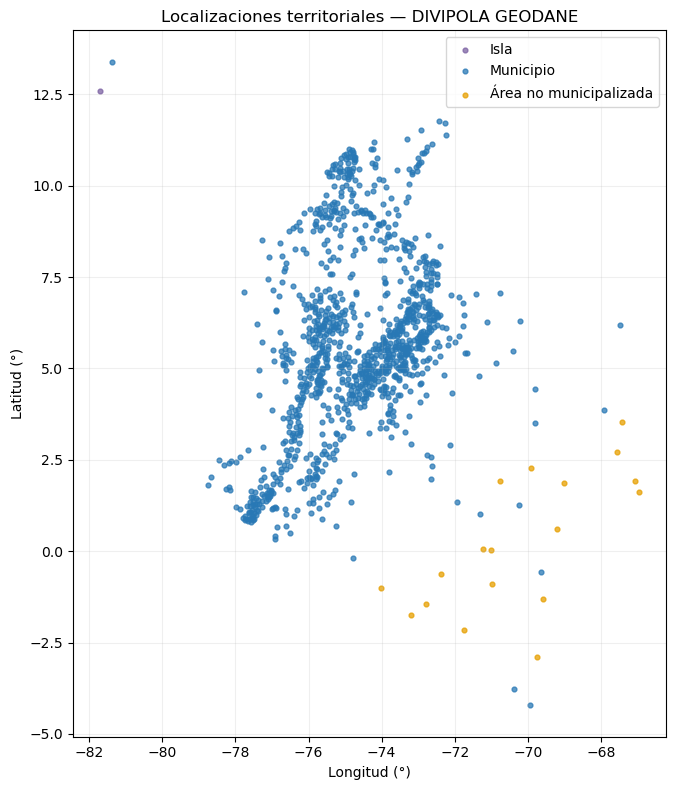

In [11]:
fig, ax = plt.subplots(figsize=(8, 8))
colores = {"Municipio": "#2878B5", "Área no municipalizada": "#E69F00", "Isla": "#7B61A2"}
for tipo, grupo in maestro.groupby("tipo_localizacion"):
    ax.scatter(grupo["longitud"], grupo["latitud"], s=12, alpha=.75,
               label=tipo, color=colores[tipo])
ax.set(xlabel="Longitud (°)", ylabel="Latitud (°)", title="Localizaciones territoriales — DIVIPOLA GEODANE")
ax.set_aspect("equal", adjustable="box")
ax.legend()
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(RESULTADOS / "maestro_control_coordenadas.png", dpi=160, bbox_inches="tight")
plt.show()

### 5. Alcance del proyecto
Se crea una columna que nos permita marcar los municipio que se van a excluird del análisis por tener mayor volumen de transaccionalidad inmobiliaria correspondiente al 1%

In [12]:
# Crear columna para registrar futuras exclusiones
maestro["exclusion_propuesta_guia4"] = ""

In [13]:
# Registrar municipios que se excluirán
# maestro.loc[maestro["divipola"] == "11001", "exclusion_propuesta_guia4"] = "Sí"

# Mostrar municipios excluidos
# display(maestro[maestro["exclusion_propuesta_guia4"] == "Sí"])

### 6. Exportación del maestro preliminar
La tabla queda lista estructuralmente, pero el universo definitivo se validará con el resultado de cobertura y el alcance acordado. CSV para facilitar la inspección; se debe leer siempre `divipola`, `cod_depto` y `cod_muni` como texto.

In [14]:
df_maestro = maestro[["divipola", "cod_depto", "cod_muni", "departamento", "municipio",
                      "tipo_localizacion", "longitud", "latitud", "exclusion_propuesta_guia4"]].sort_values("divipola").reset_index(drop=True)
ruta_salida = PROCESADOS / "00_maestro_municipios.csv"
df_maestro.to_csv(ruta_salida, index=False, encoding="utf-8-sig")
control = pd.read_csv(ruta_salida, dtype={"divipola": "string", "cod_depto": "string", "cod_muni": "string"})
assert control["divipola"].equals(df_maestro["divipola"])
print("Maestro preliminar exportado:", ruta_salida)
print("Dimensión final:", df_maestro.shape)
display(df_maestro.head(10))
assert control[["longitud", "latitud"]].notna().all().all()

Maestro preliminar exportado: C:\Users\ASUS ADMI\Downloads\11 Gerencia de Proyectos Analytics\Proyecto\proyecto_MIAD\Integracion\Datos_procesados\00_maestro_municipios.csv
Dimensión final: (1122, 9)


,divipola,cod_depto,cod_muni,departamento,municipio,tipo_localizacion,longitud,latitud,exclusion_propuesta_guia4
0,05001,05,001,ANTIOQUIA,MEDELLÍN,Municipio,-75.581775,6.246631,
1,05002,05,002,ANTIOQUIA,ABEJORRAL,Municipio,-75.428739,5.789315,
2,05004,05,004,ANTIOQUIA,ABRIAQUÍ,Municipio,-76.064304,6.632282,
3,05021,05,021,ANTIOQUIA,ALEJANDRÍA,Municipio,-75.141346,6.376061,
4,05030,05,030,ANTIOQUIA,AMAGÁ,Municipio,-75.702188,6.038708,
5,05031,05,031,ANTIOQUIA,AMALFI,Municipio,-75.077501,6.909655,
6,05034,05,034,ANTIOQUIA,ANDES,Municipio,-75.878828,5.657194,
7,05036,05,036,ANTIOQUIA,ANGELÓPOLIS,Municipio,-75.711389,6.109719,
8,05038,05,038,ANTIOQUIA,ANGOSTURA,Municipio,-75.335116,6.885175,
9,05040,05,040,ANTIOQUIA,ANORÍ,Municipio,-75.148355,7.074703,


### 7. Diccionario de datos
| Variable | Tipo | Descripción |
|---|---|---|
| divipola | Texto, 5 caracteres | Llave territorial de integración. |
| cod_depto | Texto, 2 caracteres | Código del departamento. |
| cod_muni | Texto, 3 caracteres | Últimos tres caracteres del DIVIPOLA. |
| departamento | Texto | Nombre del departamento según GEODANE. |
| municipio | Texto | Nombre territorial según GEODANE. |
| tipo_localizacion | Texto | Municipio, Isla o Área no municipalizada, según la fuente. |
| longitud | Float64 | Longitud del punto de referencia reportado, en grados decimales. |
| latitud | Float64 | Latitud del punto de referencia reportado, en grados decimales. |
| exclusion_propuesta_guia4 | Booleano | Marca de exclusión preliminar de cinco grandes ciudades, sin eliminarlas. |

Los identificadores, coordenadas y atributos administrativos se conservan para cruces, filtros y visualizaciones. 
Las coordenadas no se incorporarán automáticamente como características del clustering. Se evaluará su pertinencia si se desea modelar proximidad espacial.

### 8. Comparación con catálogo de la base de municipios utilizada anteriormente

Se comparan códigos sin modificar el universo GEODANE. Las diferencias pueden reflejar cobertura o cambios administrativos; deben revisarse antes de decidir equivalencias históricas.

In [15]:
def normalizar_codigo(serie, ancho):
    texto = serie.astype("string").str.strip().str.replace(r"\.0+$", "", regex=True)
    valido = texto.str.fullmatch(rf"[0-9]{{1,{ancho}}}", na=False)
    return texto.where(valido).str.zfill(ancho)

In [16]:
CATALOGO_ANTERIOR = ORIGINALES / "BaseMunicipiosDIVIPOLA.xlsx"
if not CATALOGO_ANTERIOR.exists():
    CATALOGO_ANTERIOR = RAIZ / "exploracion" / CATALOGO_ANTERIOR.name
if CATALOGO_ANTERIOR.exists():
    anterior = pd.read_excel(CATALOGO_ANTERIOR, dtype="string")
    anterior.columns = anterior.columns.str.strip()
    codigos_anteriores = set(normalizar_codigo(anterior["DEPTO+MPIO"], 5).dropna()) - {"00000"}
    codigos_actuales = set(maestro["divipola"])
    diferencias_catalogo = pd.DataFrame([
        {"divipola": codigo, "presencia": etiqueta}
        for etiqueta, conjunto in [("solo_geodane", codigos_actuales-codigos_anteriores),
                                  ("solo_catalogo_guia4", codigos_anteriores-codigos_actuales)]
        for codigo in sorted(conjunto)
    ], columns=["divipola", "presencia"])
    diferencias_catalogo.to_csv(RESULTADOS / "maestro_comparacion_catalogo_guia4.csv", index=False)
    print("Códigos compartidos:", len(codigos_anteriores & codigos_actuales))
    display(diferencias_catalogo)
else:
    print("Comparación pendiente: catálogo anterior no disponible.")

Códigos compartidos: 1104


,divipola,presencia
0,91263,solo_geodane
1,91405,solo_geodane
2,91407,solo_geodane
3,91430,solo_geodane
4,91460,solo_geodane
5,91530,solo_geodane
6,91536,solo_geodane
7,91669,solo_geodane
8,91798,solo_geodane
9,94883,solo_geodane
